Homework 7, problem 2, part d

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
def compute_exact_markov_stats(rates):
    """
    Computes exact E[M] and last-finisher probabilities by tracking the group
    of students still working using a memoized state recurrence.
    """
    n = len(rates)
    memo_E = {}
    memo_last = {}
    
    def get_expected_time(working_set):
        if not working_set:
            return 0.0
        if working_set in memo_E:
            return memo_E[working_set]
        
        sum_rates = sum(rates[i] for i in working_set)
        expected_holding_time = 1.0 / sum_rates
        
        expected_residual_time = 0.0
        for i in working_set:
            next_set = tuple(j for j in working_set if j != i)
            prob_i_leaves_first = rates[i] / sum_rates
            expected_residual_time += prob_i_leaves_first * get_expected_time(next_set)
            
        val = expected_holding_time + expected_residual_time
        memo_E[working_set] = val
        return val

    def get_last_probabilities(working_set):
        if working_set in memo_last:
            return memo_last[working_set]
        
        probs = np.zeros(n)
        if len(working_set) == 1:
            # if only one student remains, they are guaranteed to be last
            probs[working_set[0]] = 1.0
            return probs
            
        sum_rates = sum(rates[i] for i in working_set)
        for i in working_set:
            prob_i_leaves_first = rates[i] / sum_rates
            next_set = tuple(j for j in working_set if j != i)
            probs += prob_i_leaves_first * get_last_probabilities(next_set)
            
        memo_last[working_set] = probs
        return probs

    initial_set = tuple(range(n))
    return get_expected_time(initial_set), get_last_probabilities(initial_set)

def compute_alternating_formula_E(rates):
    """
    Computes E[M] using the alternating subset inclusion-exclusion formula.
    """
    n = len(rates)
    total_E = 0.0
    # bitmask over all 2^n - 1 non-empty subsets
    for mask in range(1, 1 << n):
        subset_sum = 0.0
        subset_cardinality = 0
        for i in range(n):
            if (mask >> i) & 1:
                subset_sum += rates[i]
                subset_cardinality += 1
        sign = (-1) ** (subset_cardinality + 1)
        total_E += sign * (1.0 / subset_sum)
    return total_E

In [3]:
rates_6 = np.arange(1, 7)  # rates lambda_i = i for i = 1, ..., 6
n_simulations = 200000

# defining exact benchmarks
exact_E_6, exact_last_probs_6 = compute_exact_markov_stats(rates_6)
alt_E_6 = compute_alternating_formula_E(rates_6)

# vectorized sampling of exponential variables
simulated_times = np.zeros((n_simulations, 6))
for i in range(6):
    simulated_times[:, i] = np.random.exponential(scale=1.0 / rates_6[i], size=n_simulations)

# extract event observables along axis arrays
sim_M = np.max(simulated_times, axis=1)
sim_first_finisher = np.argmin(simulated_times, axis=1)
sim_first_time = np.min(simulated_times, axis=1)
sim_last_finisher = np.argmax(simulated_times, axis=1)

# summary statistics
sim_E_6 = np.mean(sim_M)
sim_last_probs_6 = np.bincount(sim_last_finisher, minlength=6) / n_simulations

In [4]:
print("Part d metrics summary for k = 6 students")
print(f"Exact E[M] (Markov Chain Approach): {exact_E_6:.5f}")
print(f"Exact E[M] (Alternating Formula): {alt_E_6:.5f}")
print(f"Monte Carlo Simulated E[M] ({n_simulations:,} trials): {sim_E_6:.5f}")

print("Student Finish Last Probabilities")
print(f"{'Student ID':<12} | {'Exact Probability':<20} | {'Simulated Probability':<20}")
for i in range(6):
    print(f"Student {i+1:<4} (λ={rates_6[i]}) | {exact_last_probs_6[i]:<20.4%} | {sim_last_probs_6[i]:<20.4%}")

print("First Finisher Independence Check")
print("Mean duration of the first student to leave, isolated by who it was:")
for i in range(6):
    conditional_mean = np.mean(sim_first_time[sim_first_finisher == i])
    print(f"When Student {i+1} finished first: Mean time = {conditional_mean:.5f} (Global 1/Λ = {1/21:.5f})")

Part d metrics summary for k = 6 students
Exact E[M] (Markov Chain Approach): 1.24929
Exact E[M] (Alternating Formula): 1.24929
Monte Carlo Simulated E[M] (200,000 trials): 1.24954
Student Finish Last Probabilities
Student ID   | Exact Probability    | Simulated Probability
Student 1    (λ=1) | 52.8244%             | 52.9825%            
Student 2    (λ=2) | 22.3088%             | 22.2560%            
Student 3    (λ=3) | 11.5318%             | 11.4660%            
Student 4    (λ=4) | 6.6241%              | 6.5930%             
Student 5    (λ=5) | 4.0755%              | 4.0705%             
Student 6    (λ=6) | 2.6354%              | 2.6320%             
First Finisher Independence Check
Mean duration of the first student to leave, isolated by who it was:
When Student 1 finished first: Mean time = 0.04810 (Global 1/Λ = 0.04762)
When Student 2 finished first: Mean time = 0.04753 (Global 1/Λ = 0.04762)
When Student 3 finished first: Mean time = 0.04804 (Global 1/Λ = 0.04762)
When Stude

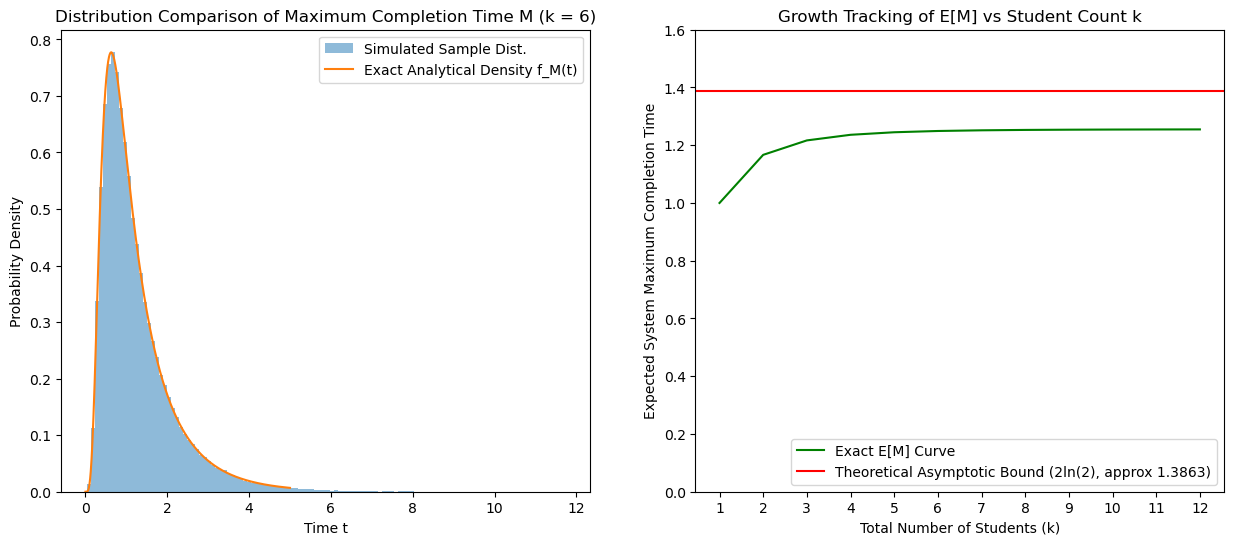

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Histogram vs Analytical Continuous Density
t_grid = np.linspace(0.001, 5.0, 1000)
# formula: f_M(t) = \prod(1 - e^{-it}) * \sum (i * e^{-it} / (1 - e^{-it}))
product_term = np.prod([1.0 - np.exp(-i * t_grid) for i in rates_6], axis=0)
summation_term = np.sum([i * np.exp(-i * t_grid) / (1.0 - np.exp(-i * t_grid)) for i in rates_6], axis = 0)
analytical_density = product_term * summation_term

ax1.hist(sim_M, bins=120, density=True, alpha=0.5, label = 'Simulated Sample Dist.')
ax1.plot(t_grid, analytical_density, label = 'Exact Analytical Density f_M(t)')
ax1.set_title('Distribution Comparison of Maximum Completion Time M (k = 6)')
ax1.set_xlabel('Time t')
ax1.set_ylabel('Probability Density')
ax1.legend()

# Scaling Analysis E[M] vs k up to k=12
k_range = np.arange(1, 13)
E_values_vs_k = [compute_alternating_formula_E(np.arange(1, k + 1)) for k in k_range]
theoretical_bound = 2.0 * np.log(2.0)

ax2.plot(k_range, E_values_vs_k, color = "green", label = 'Exact E[M] Curve')
ax2.axhline(theoretical_bound, color = "red", label = 'Theoretical Asymptotic Bound (2ln(2), approx 1.3863)')
ax2.set_title('Growth Tracking of E[M] vs Student Count k')
ax2.set_xlabel('Total Number of Students (k)')
ax2.set_ylabel('Expected System Maximum Completion Time')
ax2.set_xticks(k_range)
ax2.set_ylim(0.0, 1.6)
ax2.legend(loc = 'lower right')

plt.show()